# Исследование стартапов
- Автор: Ивченко Юлия
- Дата: 29.01.2026

## Введение


**Цель**: для финансовой компании, работающий с венчурными инвестициями помочь понять закономерности финансирования стартапов и оценить перспективы выхода на рынок с покупкой и развитием компаний.

**Задачи:**
1. Загрузить данные и познакомиться с их содержимым.
2. Провести предобработку данных.
3. Провести исследовательский анализ данных: выделить группы компаний по срокам финансирования и сравнить их по количеству и объёму инвестиций,
классифицировать сегменты рынка на массовые, средние и нишевые и учесть это в дальнейшем анализе, определить типичные и аномальные значения объёмов финансирования, исключить выбросы и ограничить период исследования, сравнить популярность и объёмы разных типов финансирования, проанализировать динамику раундов и объёмов инвестиций по годам, а также изменения в массовых сегментах рынка, рассчитать долю возврата средств для разных типов финансирования и оценить её устойчивость.
4. Сформулировать выводы по проведённому анализу и  дать рекомендации, куда и каким образом было бы целесообразно инвестировать, если бы на дворе был 2015 год.

## Шаг 1. Знакомство с данными: загрузка и предобработка

Датасет получен из базы данных стартапов.

Датасет `path_investments`, содержит информацию о компаниях и состоявшемся финансировании:

Описание данных:
* `name` — название компании.
* `homepage_url` — ссылка на сайт компании.
* `category_list` — категории, в которых работает компания. Указываются через `|`.
* `market` — основной рынок или отрасль компании.
* `funding_total_usd` — общий объём привлечённых инвестиций в долларах США.
* `status` — текущий статус компании, например `operating`, `closed` и так далее.
* `country_code` — код страны, например USA.
* `state_code` — код штата или региона, например, CA.
* `region` — регион, например, SF Bay Area.
* `city` — город, в котором расположена компания.
* `funding_rounds` — общее число раундов финансирования.
* `participants` — число участников в раундах финансирования.
* `founded_at` — дата основания компании.
* `founded_month` — месяц основания в формате `YYYY-MM`.
* `founded_quarter` — квартал основания в формате `YYYY-QN`.
* `founded_year` — год основания.
* `first_funding_at` — дата первого финансирования.
* `mid_funding_at` — дата среднего по времени раунда финансирования.
* `last_funding_at` — дата последнего финансирования.
* `seed` — сумма инвестиций на посевной стадии.
* `venture` — сумма венчурных инвестиций.
* `equity_crowdfunding` — сумма, привлечённая через долевой краудфандинг.
* `undisclosed` — сумма финансирования нераскрытого типа.
* `convertible_note` — сумма инвестиций через конвертируемые займы.
* `debt_financing` — сумма долгового финансирования.
* `angel` — сумма инвестиций от бизнес-ангелов.
* `grant` — сумма полученных грантов.
* `private_equity` — сумма инвестиций в виде прямых (частных) вложений.
* `post_ipo_equity` — сумма финансирования после IPO.
* `post_ipo_debt` — сумма долгового финансирования после IPO.
* `secondary_market` — сумма сделок на вторичном рынке.
* `product_crowdfunding` — сумма, привлечённая через продуктовый краудфандинг.
* `round_A` — `round_H` — сумма инвестиций в соответствующем раунде.

Название дополнительного датасета — `path_returns`. Он содержит суммы возвратов по типам финансирования в миллионах долларов по годам.

Описание данных:
* `year` — год возврата средств.
* `seed` — сумма возвратов от посевных инвестиций.
* `venture` — сумма возвратов от венчурных инвестиций.
* `equity_crowdfunding` — сумма, возвращённая по долевому краудфандингу.
* `undisclosed` — сумма возвратов нераскрытого типа.
* `convertible_note` — сумма возвратов через конвертируемые займы.
* `debt_financing` — сумма возвратов от долгового финансирования.
* `angel` — сумма возвратов бизнес-ангелам.
* `grant` — сумма возвратов по грантам.
* `private_equity` — сумма возвратов прямых (частных) вложений.
* `post_ipo_equity` — сумма возвратов от IPO.
* `post_ipo_debt` — сумма возвратов от долгового IPO.
* `secondary_market` — сумма возвратов от сделок на вторичном рынке.
* `product_crowdfunding` — сумма возвратов по продуктовому краудфандингу.

### Содержимое проекта

1. Загрузка данных и знакомство с ними.
2. Предобработка данных.
3. Исследовательский анализ данных.
4. Итоговые выводы.

### 1.1. Вывод общей информации

Начнём с загрузки библиотек и наборов данных cb_investments.zip и cb_returns.csv. Будем использовать pandas и библиотеки визуализации данных matplotlib и seaborn, а также phik для построения матрицы корреляции. Данные наборов данных сохраним в двух переменных: df_investments и df_returns.

In [1]:
# Импортируем библиотеки
import pandas as pd

# Загружаем библиотеки для визуализации данных
import matplotlib.pyplot as plt

In [2]:
# Выгружаем данные в переменные df_returns и df_investments
df_investments = pd.read_csv("path_investments")
df_returns = pd.read_csv('path_returns')

Выведите информацию, которая необходима для принятия решений о предобработке.

In [3]:
# Выводим первые строки датафрейма df_investments на экран 
pd.set_option('display.max_columns', None)
df_investments_shape=df_investments.shape[0]
display(df_investments.head())

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,funding_rounds,participants,founded_at,founded_month,founded_quarter,founded_year,first_funding_at,mid_funding_at,last_funding_at,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
0,Harvard University,http://harvard.edu,|Education|,Education,"9,00,00,000",operating,USA,MA,Boston,Cambridge,1.0,NaN,1636-09-08,NaN,NaN,1636.0,2014-01-06,NaN,2014-01-06,0.0,0.0,0.0,0.0,0.0,0.0,0.0,90000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,University of New Brunswick,http://www.unb.ca,NaN,NaN,"20,00,000",operating,NaN,NaN,NaN,NaN,1.0,NaN,1785-01-01,NaN,NaN,1785.0,2014-05-15,NaN,2014-05-15,0.0,2000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,Business Services,"90,00,000",operating,USA,DE,"Wilmington, Delaware",Wilmington,1.0,1.0,1802-07-19,NaN,NaN,1802.0,2009-07-02,2009-07-02,2009-07-02,0.0,9000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,University of Michigan,http://www.umich.edu/,|Education|,Education,"77,00,000",operating,USA,MI,Detroit,Ann Arbor,3.0,0.0,1817-01-01,NaN,NaN,1817.0,2013-11-21,2013-11-21,2014-11-03,0.0,0.0,0.0,1600000.0,0.0,0.0,0.0,6100000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Case Western Reserve University,http://www.case.edu,|Education|,Education,"5,40,000",operating,USA,OH,Cleveland,Cleveland,1.0,NaN,1826-01-01,NaN,NaN,1826.0,2014-01-14,NaN,2014-01-14,0.0,0.0,0.0,0.0,0.0,0.0,0.0,540000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:
# Выводим информацию о датафрейме df_investments
df_investments.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  object 
 1   homepage_url          45989 non-null  object 
 2   category_list         45477 non-null  object 
 3    market               45477 non-null  object 
 4    funding_total_usd    49438 non-null  object 
 5   status                48124 non-null  object 
 6   country_code          44165 non-null  object 
 7   state_code            30161 non-null  object 
 8   region                44165 non-null  object 
 9   city                  43322 non-null  object 
 10  funding_rounds        49438 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38554 non-null  object 
 13  founded_month         38482 non-null  object 
 14  founded_quarter       38482 non-null  object 
 15  founded_year       

Датасет df_investments содержит 40 столбцов и 54294 строк с информацией о компаниях и состоявшемся финансировании.

После первичного анализа данных можно сделать следующие выводы:

- Названия столбцов приведены к единому виду (в стиле snake case), но в 2х столбцах `market` и `funding_total_usd` вначале названия присутствует пробел, который нужно убрать.
- Данные, представленные в столбцах: `name`, `homepage_url`, `category_list`, `market`, `status`, `country_code`, `state_code`, `region`, `city` -  содержат текстовые значения и хранятся в типах данных object. Данные представлены верно.
- Данные, представленные в столбцах: `seed`, `venture`, `equity_crowdfunding`, `undisclosed`, `convertible_note`, `debt_financing`, `angel`, `grant`, `private_equity`, `post_ipo_equity`, `post_ipo_debt`, `secondary_market`, `product_crowdfunding` , `round_A` — `round_H` — содержат информацию о сумме инвестиций и хранятся в типах данных float64. Данные представлены верно.
- Значения в столбцах `funding_rounds`,`participants` представлены целыми числами, но имеют тип данных float64 — можно заменить на int и оптимизировать.
- Значения в столбце `funding_total_usd` - вещественные числовые данные, но имеют тип object - можно заменить на float64.
- Значения в столбцах `founded_at`, `founded_month`, `first_funding_at`, `mid_funding_at`, `last_funding_at` содержат дату, проэтому мы можем заменить тип данных с object на datetime.
- `founded_year` имеет тип данных float64, а так как это год, то можем заменить на целочисленный тип данных int64.
  
Пропуски встречаются во всех столбцах.

Судя по первому знакомству с данными, значения в столбцах соответствуют своему описанию.

In [5]:
# Выводим первые строки датафрейма df_returns на экран 
df_returns

,year,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
0,2000,16.70,55.40,0.00,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.00,0.20,0.00
1,2001,2.88,23.49,0.00,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.00,0.46,0.00
2,2002,6.59,209.42,0.00,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.00,0.06,0.00
3,2003,7.74,233.86,0.00,9.40,0.01,1.09,3.41,0.0,1.62,2.11,0.00,0.08,0.00
4,2004,9.93,555.90,0.00,33.19,0.01,13.55,9.18,0.0,2.19,3.38,0.00,0.55,0.00
5,2005,26.60,2628.92,0.00,9.51,0.02,35.09,31.06,0.0,2.40,3.51,0.00,0.05,0.00
6,2006,61.81,3100.18,0.19,46.74,1.78,113.21,47.75,0.0,16.67,20.58,0.00,0.12,0.00
7,2007,70.41,3585.37,0.01,55.37,3.22,125.68,164.51,0.0,88.81,24.36,0.00,0.57,0.00
8,2008,89.72,2717.02,0.03,41.02,1.71,397.54,102.83,0.0,130.38,84.28,0.00,0.47,0.00
9,2009,160.21,2501.29,0.18,37.50,2.25,394.10,97.21,0.0,203.70,76.76,0.00,0.12,0.02


In [6]:
# Выводим информацию о датафрейме df_returns
df_returns.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   year                  15 non-null     int64  
 1   seed                  15 non-null     float64
 2   venture               15 non-null     float64
 3   equity_crowdfunding   15 non-null     float64
 4   undisclosed           15 non-null     float64
 5   convertible_note      15 non-null     float64
 6   debt_financing        15 non-null     float64
 7   angel                 15 non-null     float64
 8   grant                 15 non-null     float64
 9   private_equity        15 non-null     float64
 10  post_ipo_equity       15 non-null     float64
 11  post_ipo_debt         15 non-null     float64
 12  secondary_market      15 non-null     float64
 13  product_crowdfunding  15 non-null     float64
dtypes: float64(13), int64(1)
memory usage: 1.8 KB


Датасет df_returns содержит 14 столбцов и 15 строк с информацией о сумме возвратов по типам финансирования.

После первичного анализа данных можно сделать следующие выводы:

- Названия столбцов приведены к единому виду (в стиле snake case).
- Данные, представленные в столбце `year` -  содержат целочисленные значения и хранятся в типе данных int64, можно оптимизировать. 
- Данные, представленные в столбцах: `seed`, `venture`, `equity_crowdfunding`, `undisclosed`, `convertible_note`, `debt_financing`, `angel`, `grant`, `private_equity`, `post_ipo_equity`, `post_ipo_debt`, `secondary_market`, `product_crowdfunding` хранятся в типе данных float64, тип данных верный.
  
Пропусков не встречается.

Судя по первому знакомству с данными, значения в столбцах соответствуют своему описанию.

### 1.2. Предобработка данных

Названия столбцов приведены к единому виду (в стиле snake case), но в 2х столбцах market и funding_total_usd вначале названия присутствует пробел, который нужно убрать. Выведем эти стобцы, чтобы убедиться, что присутствуют пробелы и удалиим их.

In [7]:
# выведем названия столбцов
display(df_investments.columns)

Index(['name', 'homepage_url', 'category_list', ' market ',
       ' funding_total_usd ', 'status', 'country_code', 'state_code', 'region',
       'city', 'funding_rounds', 'participants', 'founded_at', 'founded_month',
       'founded_quarter', 'founded_year', 'first_funding_at', 'mid_funding_at',
       'last_funding_at', 'seed', 'venture', 'equity_crowdfunding',
       'undisclosed', 'convertible_note', 'debt_financing', 'angel', 'grant',
       'private_equity', 'post_ipo_equity', 'post_ipo_debt',
       'secondary_market', 'product_crowdfunding', 'round_A', 'round_B',
       'round_C', 'round_D', 'round_E', 'round_F', 'round_G', 'round_H'],
      dtype='object')

In [8]:
# удалим пробелы в названиях столбцов и выведем эти названия на экран
df_investments.columns = df_investments.columns.str.strip()
display(df_investments.columns)

Index(['name', 'homepage_url', 'category_list', 'market', 'funding_total_usd',
       'status', 'country_code', 'state_code', 'region', 'city',
       'funding_rounds', 'participants', 'founded_at', 'founded_month',
       'founded_quarter', 'founded_year', 'first_funding_at', 'mid_funding_at',
       'last_funding_at', 'seed', 'venture', 'equity_crowdfunding',
       'undisclosed', 'convertible_note', 'debt_financing', 'angel', 'grant',
       'private_equity', 'post_ipo_equity', 'post_ipo_debt',
       'secondary_market', 'product_crowdfunding', 'round_A', 'round_B',
       'round_C', 'round_D', 'round_E', 'round_F', 'round_G', 'round_H'],
      dtype='object')

Значения в столбце `funding_total_usd` - вещественные числовые данные, но имеют тип object, тк в столбце выделяют рязряды. Уберем в столбце выделение разрядов и приведем его к числовому типу.

In [9]:
# уберем выделение разрядов, а имеено удалим запятые
df_investments['funding_total_usd'] = df_investments['funding_total_usd'].str.replace(',', '')
# значения в столбце приведем к числовому типу
df_investments['funding_total_usd'] = pd.to_numeric(df_investments['funding_total_usd'], errors='coerce')
display(df_investments['funding_total_usd'].dtypes)

dtype('float64')

Обработаем типы данных в столбцах, которые хранят значения даты и времени, а именно в столбцах `founded_at`, `founded_month`, `first_funding_at`, `mid_funding_at`, `last_funding_at`.

In [10]:
# значения в столбцах приведем в типу datetime
df_investments['founded_at']=pd.to_datetime(df_investments['founded_at'], format='%Y-%m-%d', errors='coerce')
df_investments['founded_month']=pd.to_datetime(df_investments['founded_month'], format='%Y-%m', errors='coerce')
df_investments['first_funding_at']=pd.to_datetime(df_investments['first_funding_at'], format='mixed', errors='coerce')
df_investments['mid_funding_at']=pd.to_datetime(df_investments['mid_funding_at'], format='mixed', errors='coerce')
df_investments['last_funding_at']=pd.to_datetime(df_investments['last_funding_at'], format='mixed', errors='coerce')

В датасете df_returns сделаем столбец year индексом всего датасета.

In [11]:
# столбец year сделаем индексом датасета
df_returns = df_returns.set_index('year')

Значения в столбцах `funding_rounds`, `participants` и `founded_year` заменим на int и оптимизируем.

In [12]:
# Оптимизируем целочисленный тип данных в столбцах funding_rounds
df_investments['funding_rounds'] = pd.to_numeric(df_investments['funding_rounds'], downcast='integer')
# Оптимизируем целочисленный тип данных в столбцах participants
df_investments['participants'] = pd.to_numeric(df_investments['participants'], downcast='integer')
# Оптимизируем целочисленный тип данных в столбцах founded_year
df_investments['founded_year'] = pd.to_numeric(df_investments['founded_year'], downcast='integer')

При первичном анализе мы обнаружили пропуски во всех столбцах. Узнаем абсолютное и относительное количество пропусков в этих столбцах. 

In [13]:
# Применяем метод isna() к датафрейму
count_pass=df_investments.isna().sum()
display(count_pass.sort_values(ascending=False))

state_code              24133
mid_funding_at          24006
participants            23821
founded_quarter         15812
founded_month           15812
founded_at              15741
founded_year            15740
funding_total_usd       13387
city                    10972
region                  10129
country_code            10129
market                   8817
category_list            8817
homepage_url             8305
status                   6170
first_funding_at         4866
last_funding_at          4862
name                     4857
post_ipo_debt            4856
round_F                  4856
round_G                  4856
round_E                  4856
round_D                  4856
round_C                  4856
round_B                  4856
round_A                  4856
product_crowdfunding     4856
secondary_market         4856
venture                  4856
post_ipo_equity          4856
private_equity           4856
grant                    4856
angel                    4856
debt_finan

In [14]:
# Подсчитываем долю строк с пропусками
doly_pass=df_investments.isna().sum() / df_investments.shape[0]
display(doly_pass.sort_values(ascending=False))

state_code              0.444487
mid_funding_at          0.442148
participants            0.438741
founded_quarter         0.291229
founded_month           0.291229
founded_at              0.289922
founded_year            0.289903
funding_total_usd       0.246565
city                    0.202085
region                  0.186558
country_code            0.186558
market                  0.162394
category_list           0.162394
homepage_url            0.152963
status                  0.113641
first_funding_at        0.089623
last_funding_at         0.089549
name                    0.089457
post_ipo_debt           0.089439
round_F                 0.089439
round_G                 0.089439
round_E                 0.089439
round_D                 0.089439
round_C                 0.089439
round_B                 0.089439
round_A                 0.089439
product_crowdfunding    0.089439
secondary_market        0.089439
venture                 0.089439
post_ipo_equity         0.089439
private_eq

Пропуски в столбце `name` составляют 9% - процент пропусков небольшой, найдем эти пропуски и удалим их.

In [15]:
# удалим пропущеные значения в столбце name
df_investments = df_investments[~df_investments['name'].isna()]

Если нам известен город, то можем найти такие заполненные значения в столбцах `country_code`, `state_code` и `region` и заменить пропуски на эти значения.

In [16]:
def city_group(row, column_name):
    if pd.isna(row[column_name]):
        group = df_investments[df_investments['city'] == row['city']]
        if not group[column_name].dropna().empty:  # Проверяем, что есть данные для заполнения
            return group[column_name].dropna().iloc[0]
        else:
            return pd.NA  # Возвращаем pd.NA, если данных нет
    else:
        return row[column_name]

df_investments.loc[:, 'country_code'] = df_investments.apply(lambda row: city_group(row, 'country_code'), axis=1)
df_investments.loc[:, 'state_code'] = df_investments.apply(lambda row: city_group(row, 'state_code'), axis=1)
df_investments.loc[:, 'region'] = df_investments.apply(lambda row: city_group(row, 'region'), axis=1)

Так же, если нам известно значения из столбца `founded_at`, мы сможем заполнить пропуски в столбцах `founded_month`, `founded_quarter` и `founded_year`.

In [17]:
# Заполняем пропуски в founded_month
df_investments['founded_month'] = df_investments['founded_month'].fillna(df_investments['founded_at'].dt.strftime('%Y-%m'))
# Заполняем пропуски в founded_quarter
df_investments['founded_quarter'] = df_investments['founded_quarter'].fillna(df_investments['founded_at'].dt.to_period('Q').astype(str))
# Заполняем пропуски в founded_year
df_investments['founded_year'] = df_investments['founded_year'].fillna(df_investments['founded_at'].dt.year)

Избавимся от тех строк, которые не несут какой-либо информации либо не содержат данных о финансированиипропуски в  столбце `funding_total_usd`.

In [18]:
# удалим пропущеные значения в столбце funding_total_usd
df_investments = df_investments[~df_investments['funding_total_usd'].isna()]

Обработаем полные дубликаты в данных.

In [19]:
# Приводим названия к нижнему регистру
df_investments['name'] = df_investments['name'].str.lower()

In [20]:
#посчитаем количество дубликатов
count_duplicated = df_investments.duplicated().sum() 
display(count_duplicated)
# отсортируем датафрейм и находим дубликаты
df_investments_sorted = df_investments.sort_values(by=df_investments.columns.tolist())
duplicates = df_investments_sorted[df_investments_sorted.duplicated(keep=False)]
display(duplicates)

np.int64(0)

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,funding_rounds,participants,founded_at,founded_month,founded_quarter,founded_year,first_funding_at,mid_funding_at,last_funding_at,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H


Явных дубликатов нет.

Заполним пропуски в значениях `mid_funding_at` на основании значений в столбцах `first_funding_at` и `last_funding_at`. В качестве нового значения вместо пропусков возьмем приблизительно середину интервала между этими двумя датами.

In [21]:
df_investments['mid_funding_at'] = df_investments.apply(lambda row: 
    row['first_funding_at'] + (row['last_funding_at'] - row['first_funding_at']) / 2 
    if pd.isna(row['mid_funding_at']) else row['mid_funding_at'], axis=1)

Оценим размер оставшихся пропусков в столбцах.

In [22]:
count_pass1=df_investments.isna().sum()
display(count_pass1.sort_values(ascending=False))

participants            13575
state_code              11933
founded_month            8707
founded_at               8707
founded_year             8706
city                     4504
country_code             3818
region                   3818
market                   2503
category_list            2503
homepage_url             2314
status                   1105
first_funding_at            2
mid_funding_at              1
secondary_market            0
post_ipo_debt               0
product_crowdfunding        0
round_A                     0
round_B                     0
name                        0
round_C                     0
round_D                     0
round_E                     0
private_equity              0
round_F                     0
round_G                     0
post_ipo_equity             0
venture                     0
grant                       0
angel                       0
debt_financing              0
convertible_note            0
undisclosed                 0
equity_cro

Удалим оставшиеся пропуски в `first_funding_at` 2 значения и `mid_funding_at` 1 значение.

In [23]:
# удалим пропущеные значения в столбце first_funding_at
df_investments = df_investments[~df_investments['first_funding_at'].isna()]
# удалим пропущеные значения в столбце mid_funding_at
df_investments = df_investments[~df_investments['mid_funding_at'].isna()]

Выведем уникальные значения из столбца `market` и их количество

In [24]:
# выведем уникальные значения и их количество
display(df_investments['market'].unique())
display(df_investments['market'].nunique())

array([' Education ', nan, ' Business Services ', ' Social Media ',
       ' Hardware + Software ', ' Biotechnology ', ' Hardware + Software',
       ' Hospitality ', ' Enterprise Software ', ' Manufacturing ',
       'Finance', ' Finance ', ' Design ', ' Utilities ', ' Nonprofits ',
       ' Software ', ' Curated Web ', ' Health Care ', ' Education',
       ' Pharmaceuticals ', ' Health and Wellness ', ' Media ',
       ' Politics ', ' Clean Technology ', 'Manufacturing',
       ' Financial Services ', ' Consumer Electronics ', ' Web Hosting ',
       'E-Commerce', ' Automotive ', ' Local Businesses ', ' E-Commerce ',
       ' Medical ', ' Fashion ', ' Banking ', 'Security ', ' Publishing ',
       ' Networking ', ' Analytics ', ' Semiconductors ',
       ' Public Relations ', ' Jewelry ', ' Nanotechnology ', ' Travel ',
       ' Public Transportation ', 'Consulting ', ' Security ',
       ' Real Estate ', ' Consulting ', 'Environmental Innovation ',
       ' Retail ', ' Restaurants '

848

В названиях сегмента рынка есть лишние пробелы вначале и конце. Уберем их.

In [25]:
# удалим пробелы в столбце и выведем количество уникальных
df_investments['market'] = df_investments['market'].str.strip()
display(df_investments['market'].nunique())

394

Оценим полноту данных и сделаем предварительный вывод о том, достаточно ли данных для решения задач проекта. 

In [26]:
#посчитаем количество удаленных строк
count_delit_row = df_investments_shape-df_investments.shape[0]
#посчитаем процент удаленных строк
perc_delit_row = round(count_delit_row/df_investments_shape*100, 2)
display(f'Количество удаленных строк: {count_delit_row}, Процент удаленных строк: {perc_delit_row} %')

'Количество удаленных строк: 13390, Процент удаленных строк: 24.66 %'

Количество уникальных значений сократилось с 848 до 394 значений.

В результате предобработки данных были выполнены следующие действия:

- Из названия столбцов удалили лишние пробелы
- Поменяли тип данных в столбце `funding_total_usd` на числовой тип и удалили пропуски в этом столбце.
- Обработали типы данных в столбцах, которые хранят значения даты и времени, а именно в столбцах `founded_at`, `founded_month`, `first_funding_at`, `mid_funding_at`, `last_funding_at`. Заполнили пропуски в значениях `mid_funding_at` на основании значений в столбцах `first_funding_at` и `last_funding_at`.
- В датасете `df_returns` сделали столбец `year` индексом всего датасета.
- Значения в столбцах funding_rounds, participants и founded_year заменили на цулочисленные и оптимизировали.
- Пропуски в столбце `name` удалили.
- Заполнили пропущенные значения в столбцах `country_code`, `state_code` и `region` на основании значений в столбце `city`.
- Заполнили пропущенные значения в столбцах `founded_month`, `founded_quarter` и `founded_year` на основании значений в столбце `founded_at`.
- Обработали полные дубликаты в данных, явных дубликатов не оказалось.
После всех обработок, мы удалили 13390 строк, что составляет 24.7%.


## Шаг 2. Инжиниринг признаков

### 2.1. Группы по срокам финансирования

Разделим все компании на три группы:

* Единичное финансирование — был всего один раунд финансирования.

* Срок финансирования до года — между первым и последним раундом финансирования прошло не более года.

* Срок финансирования более года.

In [27]:
#создадим функцию, которая разделит компании на группы и запишет в новый столбец category_rounds
def categoriz(row):
    if row['funding_rounds'] == 1:
        return 'Единичное финансирование'
    elif row['funding_rounds'] > 1:
        if (row['last_funding_at'] - row['first_funding_at']) < pd.Timedelta(days=365):
            return 'Срок финансирования до года'
        else:
            return 'Срок финансирования более года'
    else:
        return 'без категории'

df_investments['category_rounds'] = df_investments.apply(categoriz, axis=1)
display(df_investments['category_rounds'].unique())

array(['Единичное финансирование', 'Срок финансирования до года',
       'Срок финансирования более года'], dtype=object)

Найдем, количество и какой процент от общего числа компаний относится к каждой из трёх групп.

In [28]:
# Посчитаем количество уникальных категорий
df_investments['category_rounds'].value_counts()

category_rounds
Единичное финансирование          24112
Срок финансирования более года    12385
Срок финансирования до года        4407
Name: count, dtype: int64

In [29]:
# Посчитаем долю уникальных категорий
doly_cat_count=df_investments['category_rounds'].value_counts(normalize=True)*100
display(doly_cat_count)

category_rounds
Единичное финансирование          58.947780
Срок финансирования более года    30.278212
Срок финансирования до года       10.774007
Name: proportion, dtype: float64

Найдем, какую долю от общего объёма привлечённых средств получила каждая группа.

In [30]:
# Посчитаем долю от общего объёма привлечённых средств получила каждая группа.
doly_cat_funding=df_investments.groupby('category_rounds')['funding_total_usd'].sum()/df_investments['funding_total_usd'].sum()
display(doly_cat_funding)

category_rounds
Единичное финансирование          0.306198
Срок финансирования более года    0.620279
Срок финансирования до года       0.073522
Name: funding_total_usd, dtype: float64

Визуализируем соотношение этих групп по количеству компаний и по объёму инвестиций. Для визуального анализа такого распределения можно использовать столбчатые диаграммы. 

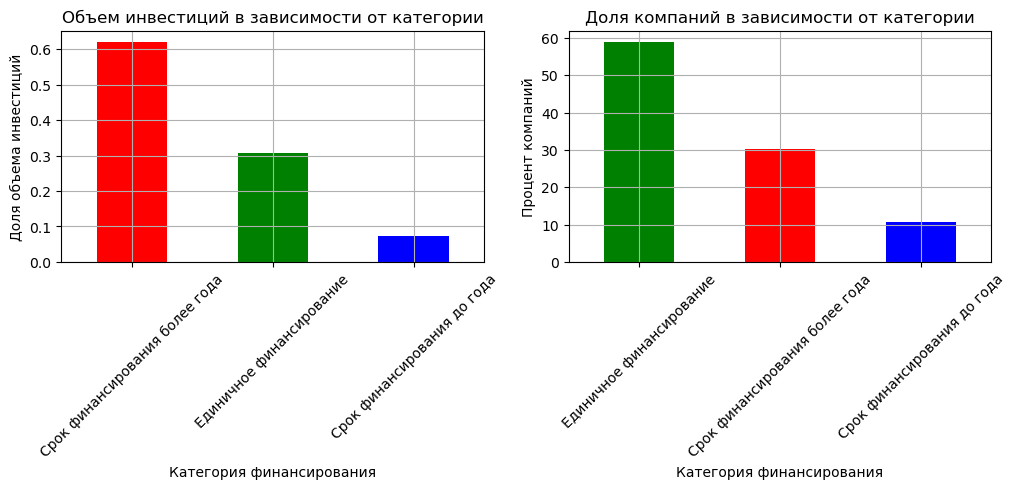

In [31]:
# Словарь для сопоставления категорий с цветами
color_dict = {
    'Единичное финансирование': 'green',
    'Срок финансирования до года': 'blue',
    'Срок финансирования более года': 'red'
}

# Создаём контейнер графика matplotlib и задаём его размер
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3))

# Первый график
doly_cat_funding.sort_values(ascending=False).plot(
    kind='bar', 
    rot=45, 
    legend=False, 
    title='Объем инвестиций в зависимости от категории',
    color=[color_dict[cat] for cat in doly_cat_funding.sort_values(ascending=False).index],
    ax=ax1  # Указываем ось для первого графика
)

# Настраиваем оформление первого графика
ax1.set_xlabel('Категория финансирования')
ax1.set_ylabel('Доля объема инвестиций')
ax1.grid()

# Второй график
doly_cat_count.sort_values(ascending=False).plot(
    kind='bar',
    rot=45,  
    legend=False,  
    title='Доля компаний в зависимости от категории',
    color=[color_dict[cat] for cat in doly_cat_count.sort_values(ascending=False).index],
    ax=ax2  # Указываем ось для второго графика
)

# Настраиваем оформление второго графика
ax2.set_xlabel('Категория финансирования')
ax2.set_ylabel('Процент компаний')
ax2.grid()

# Выводим графики
plt.show()
 

Как видим, у большинства компаний было единичное финансирование (58.9%, 24112 компаний); компаний, у которых срок финансирования более года составили 30% (12385 компаний); и компаниии, у которых срок финансирования до года - 10% (4407 компаний).
Компании, у которых срок финансирования был менее года - объем привлеченных инвестиций оказался меньше всего (7%); компании, у которых срок финансирования составил больше года - объем привлеченных инвестиций оказался самым большим (62 %); и компании, у которых было единичное финансирования - объем привлеченных инвестиций составил 31% от всей суммы инвестиций.

### 2.2 Выделение средних и нишевых сегментов рынка

Компании указывают свой сегмент рынка в столбце `market`. Рассчитаем, как часто в датасете встречается каждый из сегментов. Сегменты, к которым относится более 120 компаний, отнесите к массовым, сегменты, в которые входит от 35 до 120 включительно, отнесите к средним, а сегменты до 35 компаний отнесите к нишевым. Рассчитаем, сколько сегментов попадает в каждую из категорий.

Рассчитаем, как часто в датасете встречается каждый из сегментов. 

In [32]:
df_investments['market'].value_counts()

market
Software                  4812
Biotechnology             3590
Mobile                    2344
E-Commerce                1866
Curated Web               1693
                          ... 
Chat                         1
iPad                         1
Gadget                       1
Data Center Automation       1
Gold                         1
Name: count, Length: 394, dtype: int64

Построим график распределения количества компаний в сегментах и отобразим на нём разделение на нишевые и средние сегменты.

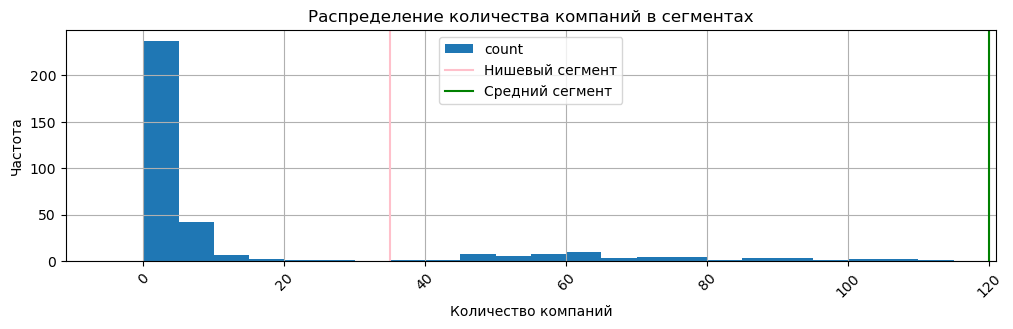

In [33]:

# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(12, 3))

# Строим гистограмму с помощью pandas через plot(kind='bar')
df_investments['market'].value_counts().plot(
               kind='hist', # Тип графика - столбчатая диаграмма
               bins= range(-5, 120, 5),
               rot=45, # Градус вращения подписи по оси Х
               title=f'Распределение количества компаний в сегментах'
)
plt.axvline(35, color='pink', label='Нишевый сегмент')
plt.axvline(120, color='green', label='Средний сегмент')
plt.legend()
# Настраиваем оформление графика
plt.xlabel('Количество компаний')
plt.ylabel('Частота')
# Добавляем сетку графика
plt.grid()

# Выводим график
plt.show()

 Теперь можно добавить столбец `category_market`, в котором отобразим к какому сегменту относится компания.

In [34]:
#создадим столбец с категорией сегментов для каждой компании
df_investments['category_market']= pd.cut(df_investments.groupby('market')['name'].transform('count'), bins=[0,35,120,50000], labels=['нишевый сегмент','средний сегмент','массовый сегмент'], right=False)
display(df_investments.head(10))

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,funding_rounds,participants,founded_at,founded_month,founded_quarter,founded_year,first_funding_at,mid_funding_at,last_funding_at,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H,category_rounds,category_market
0,harvard university,http://harvard.edu,|Education|,Education,90000000.0,operating,USA,MA,Boston,Cambridge,1.0,NaN,NaT,NaT,NaT,1636.0,2014-01-06,2014-01-06,2014-01-06,0.0,0.0,0.0,0.0,0.0,0.0,0.0,90000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,массовый сегмент
1,university of new brunswick,http://www.unb.ca,NaN,NaN,2000000.0,operating,<NA>,<NA>,<NA>,NaN,1.0,NaN,1785-01-01,1785-01-01,1785Q1,1785.0,2014-05-15,2014-05-15,2014-05-15,0.0,2000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,NaN
2,dupont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,Business Services,9000000.0,operating,USA,DE,"Wilmington, Delaware",Wilmington,1.0,1.0,1802-07-19,1802-07-01,1802Q3,1802.0,2009-07-02,2009-07-02,2009-07-02,0.0,9000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,средний сегмент
3,university of michigan,http://www.umich.edu/,|Education|,Education,7700000.0,operating,USA,MI,Detroit,Ann Arbor,3.0,0.0,1817-01-01,1817-01-01,1817Q1,1817.0,2013-11-21,2013-11-21,2014-11-03,0.0,0.0,0.0,1600000.0,0.0,0.0,0.0,6100000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Срок финансирования до года,массовый сегмент
4,case western reserve university,http://www.case.edu,|Education|,Education,540000.0,operating,USA,OH,Cleveland,Cleveland,1.0,NaN,1826-01-01,1826-01-01,1826Q1,1826.0,2014-01-14,2014-01-14,2014-01-14,0.0,0.0,0.0,0.0,0.0,0.0,0.0,540000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,массовый сегмент
5,xavier university,http://www.xavier.edu/,NaN,NaN,19000000.0,operating,USA,OH,Cincinnati,Cincinnati,1.0,NaN,1831-01-01,1831-01-01,1831Q1,1831.0,2014-10-23,2014-10-23,2014-10-23,0.0,0.0,0.0,0.0,0.0,0.0,0.0,19000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,NaN
6,tulane university,http://tulane.edu/,|Education|,Education,12000000.0,operating,USA,LA,New Orleans,New Orleans,4.0,0.0,1834-01-01,1834-01-01,1834Q1,1834.0,2013-09-05,2013-09-05,2013-12-22,0.0,0.0,0.0,0.0,0.0,0.0,0.0,12000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Срок финансирования до года,массовый сегмент
7,duke university,http://www.duke.edu,|Education|,Education,8700000.0,operating,USA,NC,Raleigh,Durham,1.0,NaN,1838-01-01,1838-01-01,1838Q1,1838.0,2014-01-12,2014-01-12,2014-01-12,0.0,8700000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,массовый сегмент
8,"virginia commonwealth university, richmond",http://www.vcu.edu/,NaN,NaN,6000000.0,operating,USA,VA,Richmond,Richmond,1.0,NaN,1838-01-01,1838-01-01,1838Q1,1838.0,2014-09-30,2014-09-30,2014-09-30,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,NaN
9,wegame,http://www.WeGame.com,|Social Media|,Social Media,3500000.0,acquired,USA,CA,SF Bay Area,San Francisco,2.0,2.0,1840-01-01,1840-01-01,1840Q1,1840.0,2007-10-01,2007-10-01,2008-03-01,500000.0,3000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Срок финансирования до года,массовый сегмент


Рассчитаем, сколько сегментов попадает в каждую из категорий.

In [35]:
# расчитаем количество сегментов в каждой категории
df_investments['category_market'].value_counts()

category_market
массовый сегмент    33732
средний сегмент      3839
нишевый сегмент       830
Name: count, dtype: int64

In [36]:
# расчитаем долю сегментов в каждой категории
df_investments['category_market'].value_counts(normalize=True)

category_market
массовый сегмент    0.878415
средний сегмент     0.099971
нишевый сегмент     0.021614
Name: proportion, dtype: float64

Построим столбчатую диаграмму количества сегментов в каждой категории.

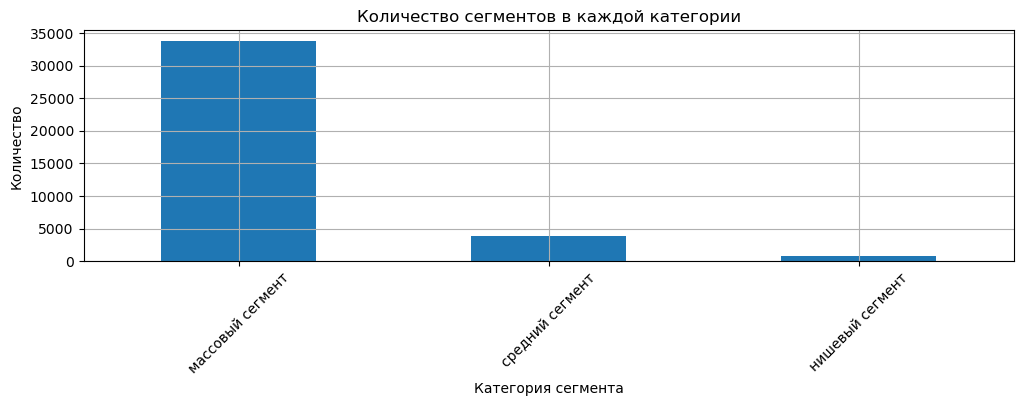

In [37]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(12, 3))

# Строим столбчатую диаграмму с помощью pandas через plot(kind='bar')
df_investments['category_market'].value_counts().sort_values(ascending=False).plot(
               kind='bar', # Тип графика - столбчатая диаграмма
               rot=45, # Градус вращения подписи по оси Х
               legend=False, # Выключаем легенду
               title=f'Количество сегментов в каждой категории'
)

# Настраиваем оформление графика
plt.xlabel('Категория сегмента')
plt.ylabel('Количество')
# Добавляем сетку графика
plt.grid()

# Выводим график
plt.show()

Построим столбчатую диаграмму доли сегментов в каждой категории.

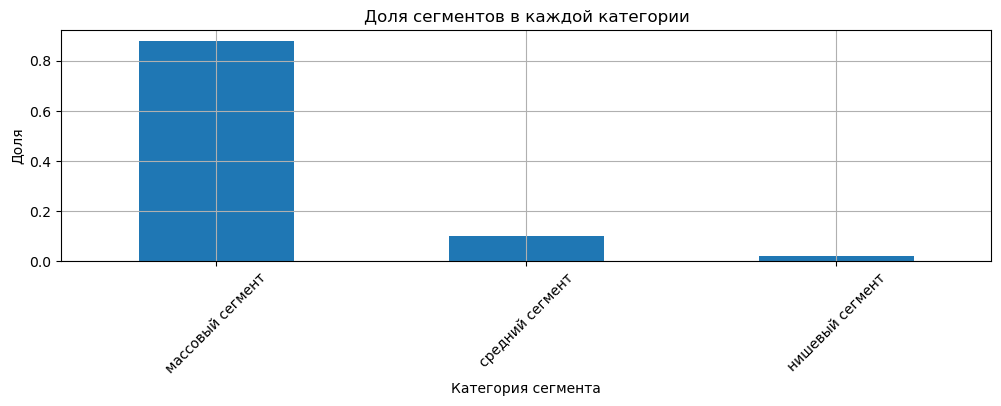

In [38]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(12, 3))

# Строим столбчатую диаграмму с помощью pandas через plot(kind='bar')
df_investments['category_market'].value_counts(normalize=True).sort_values(ascending=False).plot(
               kind='bar', # Тип графика - столбчатая диаграмма
               rot=45, # Градус вращения подписи по оси Х
               legend=False, # Выключаем легенду
               title=f'Доля сегментов в каждой категории'
)

# Настраиваем оформление графика
plt.xlabel('Категория сегмента')
plt.ylabel('Доля')
# Добавляем сетку графика
plt.grid()

# Выводим график
plt.show()

Оставим в столбце `market` только массовые сегменты. Для остальных сегментов заменим значения на заглушки — `niche` для нишевых и `mid` для средних.


In [39]:
# создадим функцию
def replace_segments(category, market_value):
    if category == 'массовый сегмент':
        return market_value
    elif category == 'средний сегмент':
        return 'mid'
    elif category == 'нишевый сегмент':
        return 'niche'
    else:
        return None

# Применяем функцию, передавая два аргумента: категорию и соответствующее значение из market
df_investments['market'] = df_investments.apply(lambda row: replace_segments(row['category_market'], row['market']), axis=1)

Основное количество компаний сосредоточено в массовом сегменте - 33732 компаний (доля составляет 0,81), в среднем сегменте - 3839 компаний и в нишевом - 830. По гистограмме видим, что в нишевом сегменте количество от 0 до 5ти компаний встречается чаще остальных.

## Шаг 3. Работа с выбросами и анализ

### 3.1. Анализируем и помечаем выбросы в каждом из сегментов

Заказчика интересует обычный для рассматриваемого периода размер средств, который предоставлялся компаниям.

По предобработанному столбцу `funding_total_usd` графическим образом оценим, какой размер общего финансирования для одной компании будет типичным, а какой — выбивающимся. Укажем интервал, в котором лежат типичные значения.

In [40]:
# Изучаем статистические показатели столбца funding_total_usd
print('Статистические показатели столбца funding_total_usd:')
df_investments['funding_total_usd'].describe()

Статистические показатели столбца funding_total_usd:


count    4.090400e+04
mean     1.591285e+07
std      1.686850e+08
min      1.000000e+00
25%      3.500000e+05
50%      2.000000e+06
75%      1.000000e+07
max      3.007950e+10
Name: funding_total_usd, dtype: float64

Можно предположить, что данные о размере общего финансирования имеют правоассиметричное распределение. Об этом говорит смещение среднего относительно медианного значений. Значение стандартного отклонения довольно высокое — 1.686850e+08, и при среднем 1.591285e+07 это указывает, что данные могут иметь широкий разброс. Разница между минимальным и максимальным значениями это подтверждает, минимальное 1, максимальное 3.007950e+10.

Дополнительно проверим это и построим  диаграмму размаха для столбца с балансом.

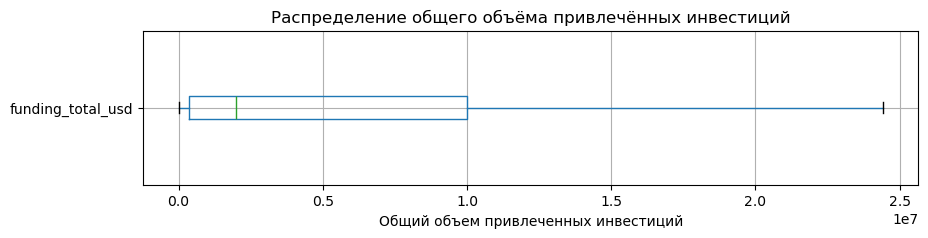

In [41]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(10, 2))

# Строим диаграмму размаха значений в столбце balance
df_investments.boxplot(column='funding_total_usd', vert=False, showfliers=False)

# Добавляем заголовок и метки оси
plt.title('Распределение общего объёма привлечённых инвестиций')
plt.xlabel('Общий объем привлеченных инвестиций')

# Выводим график
plt.show()

Распределение данных действительно выглядит ассиметриячным и характеризуется широким разбросом и «хвостом» в правой части гистограммы. Значения, которые выще 25млн можно отнести к выбросам. Медианное значение - 2млн.

Определим компании с аномальным объёмом общего финансирования — используем метод IQR отдельно по каждому сегменту. 

Для каждого сегмента посчитаем верхнюю границу, нижняя граница равна 0, а минимальное значение больше 0, поэтому проверяем значения только по верхней границе, и потом для каждой компании определим аномальный или нормальный объём общего финансирования.

In [42]:
#определим для каждого сегмента верхнюю границу
df_investments['upper_limit'] = df_investments.groupby('market')['funding_total_usd'].transform(lambda x: 
                                                    x.quantile(0.75) + 1.5 * (x.quantile(0.75) - x.quantile(0.25)))
#создадим столбец, в котором - если значение общего объема финансирования выходит за верхнюю границу, то будет True
df_investments['anomal'] = df_investments['upper_limit'] < df_investments['funding_total_usd']
#выведем датафрейм с аномальным финансированием компаний
display(df_investments[df_investments['anomal']==True])

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,funding_rounds,participants,founded_at,founded_month,founded_quarter,founded_year,first_funding_at,mid_funding_at,last_funding_at,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H,category_rounds,category_market,upper_limit,anomal
0,harvard university,http://harvard.edu,|Education|,Education,90000000.0,operating,USA,MA,Boston,Cambridge,1.0,NaN,NaT,NaT,NaT,1636.0,2014-01-06,2014-01-06,2014-01-06,0.0,0.0,0.0,0.0,0.0,0.0,0.0,90000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,массовый сегмент,1.182108e+07,True
6,tulane university,http://tulane.edu/,|Education|,Education,12000000.0,operating,USA,LA,New Orleans,New Orleans,4.0,0.0,1834-01-01,1834-01-01,1834Q1,1834.0,2013-09-05,2013-09-05,2013-12-22,0.0,0.0,0.0,0.0,0.0,0.0,0.0,12000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Срок финансирования до года,массовый сегмент,1.182108e+07,True
10,videosurf,http://www.videosurf.com,|Hardware + Software|,Hardware + Software,28000000.0,acquired,USA,CA,SF Bay Area,San Mateo,1.0,10.0,1840-09-02,1840-09-01,1840Q3,1840.0,2011-01-01,2011-01-01,2011-01-01,0.0,28000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,массовый сегмент,2.679238e+07,True
17,university of maryland,http://umd.edu,|Education|,Education,750500000.0,operating,USA,MD,"Washington, D.C.",College Park,2.0,1.0,1856-01-01,1856-01-01,1856Q1,1856.0,2013-09-17,2013-09-17,2014-02-06,0.0,0.0,0.0,0.0,0.0,0.0,0.0,750500000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Срок финансирования до года,массовый сегмент,1.182108e+07,True
20,great atlantic & pacific tea,http://aptea.com,|Hospitality|,Hospitality,175000000.0,operating,USA,NJ,Newark,Montvale,1.0,NaN,1859-01-01,1859-01-01,1859Q1,1859.0,2009-08-14,2009-08-14,2009-08-14,0.0,175000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,массовый сегмент,1.726250e+07,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49344,4:33 creative lab,http://433.co.kr,|Mobile Games|Design|Game|,Design,100000000.0,operating,KOR,<NA>,Seoul,Seoul,1.0,NaN,NaT,NaT,NaT,NaN,2014-11-13,2014-11-13,2014-11-13,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,массовый сегмент,1.251000e+07,True
49360,beigene,http://www.beigene.com/,|Biotechnology|,Biotechnology,75000000.0,operating,CHN,<NA>,Beijing,Beijing,1.0,NaN,NaT,NaT,NaT,NaN,2014-11-15,2014-11-15,2014-11-15,0.0,75000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,75000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,массовый сегмент,5.282918e+07,True
49362,blockstream,http://blockstream.com/,|Payments|Bitcoin|,mid,21000000.0,operating,CAN,QC,Montreal,Montréal,1.0,NaN,NaT,NaT,NaT,NaN,2014-11-17,2014-11-17,2014-11-17,21000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,средний сегмент,1.908762e+07,True
49378,ambiopharm,http://ambiopharm.com,|Pharmaceuticals|,mid,23999970.0,operating,USA,SC,SC - Other,North Augusta,1.0,NaN,NaT,NaT,NaT,NaN,2014-11-19,2014-11-19,2014-11-19,0.0,23999970.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,средний сегмент,1.908762e+07,True


4871 компаний с аномальным объемом общего финансирования. Определим сегменты рынка с наибольшей долей компаний, получивших аномальное финансирование, и выведим топ таких сегментов.

In [43]:
#создадим столбец, в котором - если значение общего объема финансирования выходит за верхнюю границу, то будет True
doly_anomal=df_investments.groupby('market')['anomal'].sum()/df_investments.groupby('market')['anomal'].count()
display(doly_anomal.sort_values(ascending=False))

market
Real Estate             0.172043
Entertainment           0.166667
Consulting              0.166189
Search                  0.164948
Cloud Computing         0.164474
Photography             0.161765
SaaS                    0.161765
Technology              0.159664
Video                   0.159574
niche                   0.159036
Travel                  0.154545
Networking              0.153846
Internet                0.153527
Big Data                0.153333
Marketplaces            0.153061
mid                     0.144829
E-Commerce              0.144159
Apps                    0.143498
Automotive              0.141935
Medical                 0.139073
Sports                  0.137255
Social Media            0.135593
News                    0.132890
Education               0.132701
Fashion                 0.132013
Mobile                  0.131826
Hospitality             0.130952
Health and Wellness     0.129439
Messaging               0.128814
Startups                0.128788
Cle

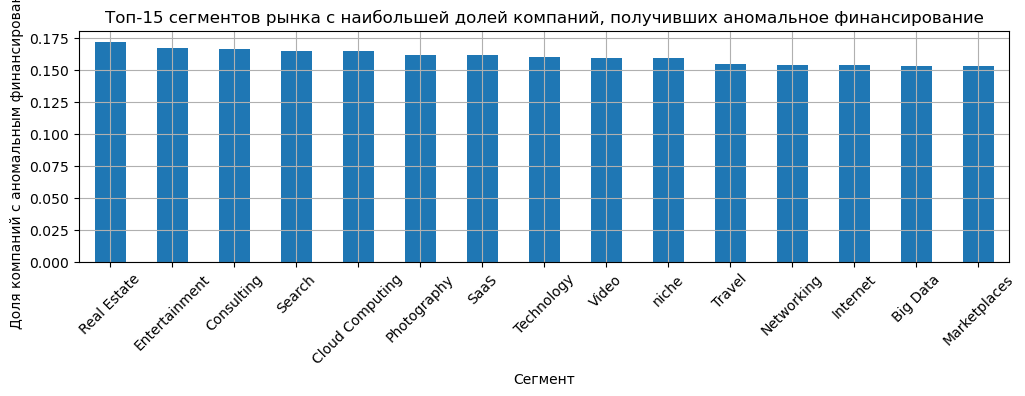

In [44]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(12, 3))

# Строим столбчатую диаграмму с помощью pandas через plot(kind='bar')
doly_anomal.sort_values(ascending=False).head(15).plot(
               kind='bar', # Тип графика - столбчатая диаграмма
               rot=45, # Градус вращения подписи по оси Х
               legend=False, # Выключаем легенду
               title=f'Топ-15 сегментов рынка с наибольшей долей компаний, получивших аномальное финансирование'
)

# Настраиваем оформление графика
plt.xlabel('Сегмент')
plt.ylabel('Доля компаний с аномальным финансированием')
# Добавляем сетку графика
plt.grid()

# Выводим график
plt.show()

Самая большая доля аномальных значений общего объема финансирования в сегменте Real Estate (0.172043), Entertainment (0.166667) и Consulting (0.166189). Меньше всего аномальных значений - Web Hosting (0.101415), Nonprofits (0.096296) и Semiconductors (0.070248)

### 3.2 Определяем границы рассматриваемого периода, отбрасываем аномалии

Проверим по датасету полноту данные за 2014 год. 

In [45]:
df_investments[['first_funding_at', 'mid_funding_at', 'last_funding_at']].max()

first_funding_at   2014-12-31
mid_funding_at     2014-12-31
last_funding_at    2014-12-31
dtype: datetime64[ns]

Последние даты 31.12.2014, то есть данны представлены полностью до конца 2014 года.

Теперь исключим из датасета компании, которые получили аномальное финансирование.

In [46]:
df_investments=df_investments[df_investments['anomal']==False]
display(df_investments)

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,funding_rounds,participants,founded_at,founded_month,founded_quarter,founded_year,first_funding_at,mid_funding_at,last_funding_at,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H,category_rounds,category_market,upper_limit,anomal
1,university of new brunswick,http://www.unb.ca,NaN,None,2000000.0,operating,<NA>,<NA>,<NA>,NaN,1.0,NaN,1785-01-01,1785-01-01,1785Q1,1785.0,2014-05-15,2014-05-15,2014-05-15,0.0,2000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,NaN,NaN,False
2,dupont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,mid,9000000.0,operating,USA,DE,"Wilmington, Delaware",Wilmington,1.0,1.0,1802-07-19,1802-07-01,1802Q3,1802.0,2009-07-02,2009-07-02,2009-07-02,0.0,9000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,средний сегмент,19087625.00,False
3,university of michigan,http://www.umich.edu/,|Education|,Education,7700000.0,operating,USA,MI,Detroit,Ann Arbor,3.0,0.0,1817-01-01,1817-01-01,1817Q1,1817.0,2013-11-21,2013-11-21,2014-11-03,0.0,0.0,0.0,1600000.0,0.0,0.0,0.0,6100000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Срок финансирования до года,массовый сегмент,11821079.25,False
4,case western reserve university,http://www.case.edu,|Education|,Education,540000.0,operating,USA,OH,Cleveland,Cleveland,1.0,NaN,1826-01-01,1826-01-01,1826Q1,1826.0,2014-01-14,2014-01-14,2014-01-14,0.0,0.0,0.0,0.0,0.0,0.0,0.0,540000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,массовый сегмент,11821079.25,False
5,xavier university,http://www.xavier.edu/,NaN,None,19000000.0,operating,USA,OH,Cincinnati,Cincinnati,1.0,NaN,1831-01-01,1831-01-01,1831Q1,1831.0,2014-10-23,2014-10-23,2014-10-23,0.0,0.0,0.0,0.0,0.0,0.0,0.0,19000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49433,riversilica,http://riversilica.com,NaN,None,1500000.0,operating,IND,<NA>,Bangalore,Bangalore,1.0,NaN,NaT,NaT,NaT,NaN,2014-12-01,2014-12-01,2014-12-01,0.0,1500000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,NaN,NaN,False
49434,southgobi resources,http://southgobi.com,|Mining Technologies|,niche,9000000.0,operating,CAN,BC,Vancouver,Vancouver,1.0,NaN,NaT,NaT,NaT,NaN,2014-12-01,2014-12-01,2014-12-01,0.0,9000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,нишевый сегмент,13244318.75,False
49435,digibyte,http://digibyte.co,NaN,None,250000.0,operating,USA,CA,Los Angeles,Santa Monica,1.0,NaN,NaT,NaT,NaT,NaN,2014-12-02,2014-12-02,2014-12-02,0.0,250000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,NaN,NaN,False
49436,xeltis,http://xeltis.com,NaN,None,34000000.0,operating,CHE,<NA>,Zurich,Zürich,1.0,NaN,NaT,NaT,NaT,NaN,2014-12-02,2014-12-02,2014-12-02,0.0,34000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,34000000.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,NaN,NaN,False


Аномальные записи удалили, теперь на основе столбцов `mid_funding_at` и `funding_rounds` оставим в датасете данные только об определённых компаниях. Они должны были получать финансирование в годы, когда было зафиксировано 50 или более раундов финансирования.

In [47]:
# Выделяем из даты только год и находим количество раундов за год
mid_funding_year = df_investments['mid_funding_at'].dt.year
grouped_sums = df_investments.groupby(mid_funding_year)['funding_rounds'].sum()
# Создаём маску для фильтрации
filter_mask = mid_funding_year.map(grouped_sums) >= 50
# Применяем маску к датафрейму
df_investments = df_investments[filter_mask]
display(df_investments)

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,funding_rounds,participants,founded_at,founded_month,founded_quarter,founded_year,first_funding_at,mid_funding_at,last_funding_at,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H,category_rounds,category_market,upper_limit,anomal
1,university of new brunswick,http://www.unb.ca,NaN,None,2000000.0,operating,<NA>,<NA>,<NA>,NaN,1.0,NaN,1785-01-01,1785-01-01,1785Q1,1785.0,2014-05-15,2014-05-15,2014-05-15,0.0,2000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,NaN,NaN,False
2,dupont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,mid,9000000.0,operating,USA,DE,"Wilmington, Delaware",Wilmington,1.0,1.0,1802-07-19,1802-07-01,1802Q3,1802.0,2009-07-02,2009-07-02,2009-07-02,0.0,9000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,средний сегмент,19087625.00,False
3,university of michigan,http://www.umich.edu/,|Education|,Education,7700000.0,operating,USA,MI,Detroit,Ann Arbor,3.0,0.0,1817-01-01,1817-01-01,1817Q1,1817.0,2013-11-21,2013-11-21,2014-11-03,0.0,0.0,0.0,1600000.0,0.0,0.0,0.0,6100000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Срок финансирования до года,массовый сегмент,11821079.25,False
4,case western reserve university,http://www.case.edu,|Education|,Education,540000.0,operating,USA,OH,Cleveland,Cleveland,1.0,NaN,1826-01-01,1826-01-01,1826Q1,1826.0,2014-01-14,2014-01-14,2014-01-14,0.0,0.0,0.0,0.0,0.0,0.0,0.0,540000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,массовый сегмент,11821079.25,False
5,xavier university,http://www.xavier.edu/,NaN,None,19000000.0,operating,USA,OH,Cincinnati,Cincinnati,1.0,NaN,1831-01-01,1831-01-01,1831Q1,1831.0,2014-10-23,2014-10-23,2014-10-23,0.0,0.0,0.0,0.0,0.0,0.0,0.0,19000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49433,riversilica,http://riversilica.com,NaN,None,1500000.0,operating,IND,<NA>,Bangalore,Bangalore,1.0,NaN,NaT,NaT,NaT,NaN,2014-12-01,2014-12-01,2014-12-01,0.0,1500000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,NaN,NaN,False
49434,southgobi resources,http://southgobi.com,|Mining Technologies|,niche,9000000.0,operating,CAN,BC,Vancouver,Vancouver,1.0,NaN,NaT,NaT,NaT,NaN,2014-12-01,2014-12-01,2014-12-01,0.0,9000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,нишевый сегмент,13244318.75,False
49435,digibyte,http://digibyte.co,NaN,None,250000.0,operating,USA,CA,Los Angeles,Santa Monica,1.0,NaN,NaT,NaT,NaT,NaN,2014-12-02,2014-12-02,2014-12-02,0.0,250000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,NaN,NaN,False
49436,xeltis,http://xeltis.com,NaN,None,34000000.0,operating,CHE,<NA>,Zurich,Zürich,1.0,NaN,NaT,NaT,NaT,NaN,2014-12-02,2014-12-02,2014-12-02,0.0,34000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,34000000.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,NaN,NaN,False


### 3.3. Анализ типов финансирования по объёму и популярности
Найдем, какие типы финансирования в сумме привлекли больше всего денег и на этом же гарфике построим столбчатую диаграмму, который покажет популярность разных типов финансирования — какие типы финансирования чаще всего используются компаниями, то есть встречаются в датасете наибольшее количество раз. 

In [48]:
#найдлем сумму типов финансирования, используемые компанией
df_investments[['seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note', 'debt_financing', 'angel',
              'grant', 'private_equity', 'post_ipo_equity', 'post_ipo_debt', 'secondary_market', 'product_crowdfunding']].sum().sort_values(ascending=False)

venture                 1.339872e+11
debt_financing          1.430518e+10
seed                    9.494103e+09
private_equity          9.244413e+09
post_ipo_equity         5.099300e+09
post_ipo_debt           4.286718e+09
undisclosed             2.924353e+09
angel                   2.501264e+09
grant                   2.168263e+09
convertible_note        5.671449e+08
equity_crowdfunding     2.629606e+08
product_crowdfunding    1.933103e+08
secondary_market        1.240862e+08
dtype: float64

In [49]:
#найдлем количество типов финансирования, используемые компанией
(df_investments[['seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note', 'debt_financing', 'angel',
              'grant', 'private_equity', 'post_ipo_equity', 'post_ipo_debt', 'secondary_market', 'product_crowdfunding']]>0).sum().sort_values(ascending=False)

venture                 19060
seed                    13387
debt_financing           3312
angel                    2938
grant                    1020
undisclosed               834
private_equity            679
convertible_note          522
equity_crowdfunding       516
product_crowdfunding      205
post_ipo_equity           177
post_ipo_debt              29
secondary_market            8
dtype: int64

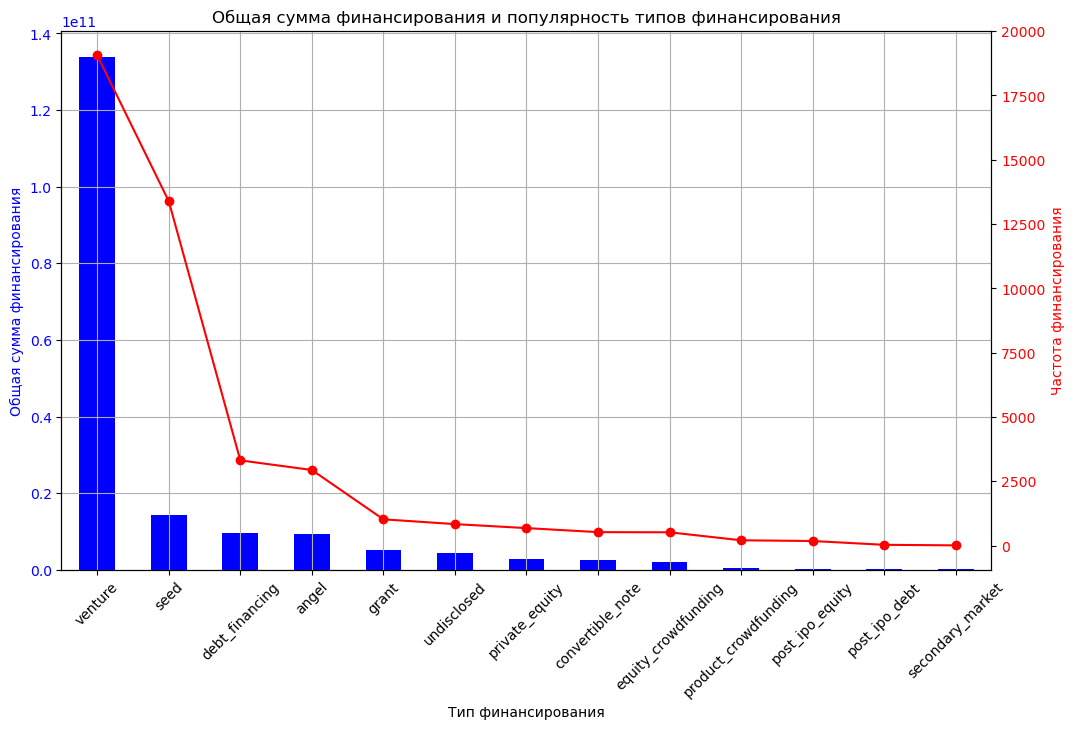

In [50]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(12, 7))

# Строим первый график общей суммы финансирования
ax1 = plt.gca()  # Получаем текущую ось
total_funding = df_investments[['seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note', 'debt_financing', 'angel',
                               'grant', 'private_equity', 'post_ipo_equity', 'post_ipo_debt', 'secondary_market', 'product_crowdfunding']].sum().sort_values(ascending=False)
total_funding.plot(kind='bar', rot=45, legend=False, title='Общая сумма финансирования и популярность типов финансирования', ax=ax1, color='blue')

# Настраиваем оформление первого графика
ax1.set_xlabel('Тип финансирования')
ax1.set_ylabel('Общая сумма финансирования', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

# Добавляем сетку для первого графика
ax1.grid()

# Второй график на второй оси (twinx)
ax2 = ax1.twinx()  # Создаём вторую ось, связанную с первой
popularity = (df_investments[['seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note', 'debt_financing', 'angel',
                             'grant', 'private_equity', 'post_ipo_equity', 'post_ipo_debt', 'secondary_market', 'product_crowdfunding']] > 0).sum().sort_values(ascending=False)
popularity.plot(kind='line', color='red', marker='o', ax=ax2)

# Настраиваем оформление второго графика
ax2.set_ylabel('Частота финансирования', color='red')
ax2.tick_params(axis='y', labelcolor='red')

# Выводим график
plt.show()
 

venture,  seed , debt_financing наиболее используемые типы финансирования и общая сумма финансирования по этим типам самая большая. secondary_market  практически не используется и сумма финансирования сама маленькая.
Тип финансирования grant компании используют часто, но общая сумма финансирования небольшая. И наоборот тип финансирования post_ipo_equity и post_ipo_debt практически не используют компании, но общая сумма финансирования по этому типу значительная.

Построим график суммарных объёмов возвратов от разных типов финансирования за весь период на основе дополнительного датасета.

In [51]:
# найдем суммарные объемы возвратов от разных типов финансирования
df_returns.sum().sort_values(ascending=False)

venture                 40578.62
debt_financing           4734.85
private_equity           3587.33
seed                     2382.24
angel                    1509.23
post_ipo_equity          1104.96
undisclosed               730.88
post_ipo_debt              91.03
convertible_note           34.79
secondary_market            5.20
equity_crowdfunding         3.83
product_crowdfunding        1.86
grant                       0.00
dtype: float64

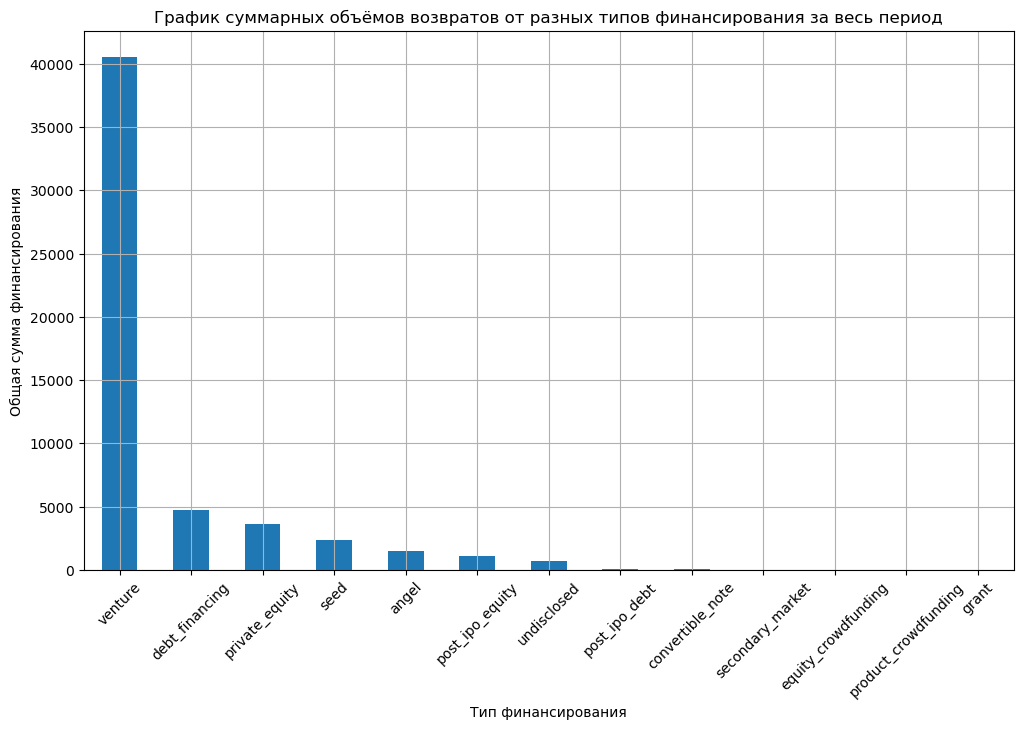

In [52]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(12, 7))

# Строим столбчатую диаграмму с помощью pandas через plot(kind='bar')
df_returns.sum().sort_values(ascending=False).plot(
               kind='bar', # Тип графика - столбчатая диаграмма
               rot=45, # Градус вращения подписи по оси Х
               legend=False, # Выключаем легенду
               title=f'График суммарных объёмов возвратов от разных типов финансирования за весь период'
)

# Настраиваем оформление графика
plt.xlabel('Тип финансирования')
plt.ylabel('Общая сумма финансирования')
# Добавляем сетку графика
plt.grid()

# Выводим график
plt.show()

Самые большие суммарные объёмы возвратов за весь период от типа финансирования venture. За тип финансирования grant суммарные объёмы возвратов за весь период составляют 0.

## Шаг 4. Анализ динамики

### 4.1 Динамика предоставления финансирования по годам

Используя столбцы `funding_total_usd` и `funding_rounds`, рассчитаем для каждой компании средний объём одного раунда финансирования.

In [53]:
# рассчитаем для каждой компании средний объём одного раунда финансирования и запишем в столбец funding_avg_usd и 
df_investments['funding_avg_usd']=df_investments['funding_total_usd']/df_investments['funding_rounds']
display(df_investments)

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,funding_rounds,participants,founded_at,founded_month,founded_quarter,founded_year,first_funding_at,mid_funding_at,last_funding_at,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H,category_rounds,category_market,upper_limit,anomal,funding_avg_usd
1,university of new brunswick,http://www.unb.ca,NaN,None,2000000.0,operating,<NA>,<NA>,<NA>,NaN,1.0,NaN,1785-01-01,1785-01-01,1785Q1,1785.0,2014-05-15,2014-05-15,2014-05-15,0.0,2000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,NaN,NaN,False,2.000000e+06
2,dupont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,mid,9000000.0,operating,USA,DE,"Wilmington, Delaware",Wilmington,1.0,1.0,1802-07-19,1802-07-01,1802Q3,1802.0,2009-07-02,2009-07-02,2009-07-02,0.0,9000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,средний сегмент,19087625.00,False,9.000000e+06
3,university of michigan,http://www.umich.edu/,|Education|,Education,7700000.0,operating,USA,MI,Detroit,Ann Arbor,3.0,0.0,1817-01-01,1817-01-01,1817Q1,1817.0,2013-11-21,2013-11-21,2014-11-03,0.0,0.0,0.0,1600000.0,0.0,0.0,0.0,6100000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Срок финансирования до года,массовый сегмент,11821079.25,False,2.566667e+06
4,case western reserve university,http://www.case.edu,|Education|,Education,540000.0,operating,USA,OH,Cleveland,Cleveland,1.0,NaN,1826-01-01,1826-01-01,1826Q1,1826.0,2014-01-14,2014-01-14,2014-01-14,0.0,0.0,0.0,0.0,0.0,0.0,0.0,540000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,массовый сегмент,11821079.25,False,5.400000e+05
5,xavier university,http://www.xavier.edu/,NaN,None,19000000.0,operating,USA,OH,Cincinnati,Cincinnati,1.0,NaN,1831-01-01,1831-01-01,1831Q1,1831.0,2014-10-23,2014-10-23,2014-10-23,0.0,0.0,0.0,0.0,0.0,0.0,0.0,19000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,NaN,NaN,False,1.900000e+07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49433,riversilica,http://riversilica.com,NaN,None,1500000.0,operating,IND,<NA>,Bangalore,Bangalore,1.0,NaN,NaT,NaT,NaT,NaN,2014-12-01,2014-12-01,2014-12-01,0.0,1500000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,NaN,NaN,False,1.500000e+06
49434,southgobi resources,http://southgobi.com,|Mining Technologies|,niche,9000000.0,operating,CAN,BC,Vancouver,Vancouver,1.0,NaN,NaT,NaT,NaT,NaN,2014-12-01,2014-12-01,2014-12-01,0.0,9000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,нишевый сегмент,13244318.75,False,9.000000e+06
49435,digibyte,http://digibyte.co,NaN,None,250000.0,operating,USA,CA,Los Angeles,Santa Monica,1.0,NaN,NaT,NaT,NaT,NaN,2014-12-02,2014-12-02,2014-12-02,0.0,250000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,NaN,NaN,False,2.500000e+05
49436,xeltis,http://xeltis.com,NaN,None,34000000.0,operating,CHE,<NA>,Zurich,Zürich,1.0,NaN,NaT,NaT,NaT,NaN,2014-12-02,2014-12-02,2014-12-02,0.0,34000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,34000000.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,NaN,NaN,False,3.400000e+07


На основе получившейся таблицы построим график "Динамика типичного размера средств, которые стартапы получали в рамках одного раунда финансирования"

In [54]:
#  находим среднее размера средств, которые стартапы получали в рамках одного раунда финансирования
df_investments.groupby(df_investments['mid_funding_at'].dt.year)['funding_avg_usd'].mean()

mid_funding_at
2000    5.016329e+06
2001    3.677063e+06
2002    4.703472e+06
2003    3.196894e+06
2004    5.170620e+06
2005    5.855185e+06
2006    5.395172e+06
2007    5.010019e+06
2008    4.396660e+06
2009    3.743000e+06
2010    3.797063e+06
2011    2.820921e+06
2012    2.573219e+06
2013    2.211419e+06
2014    3.741692e+06
Name: funding_avg_usd, dtype: float64

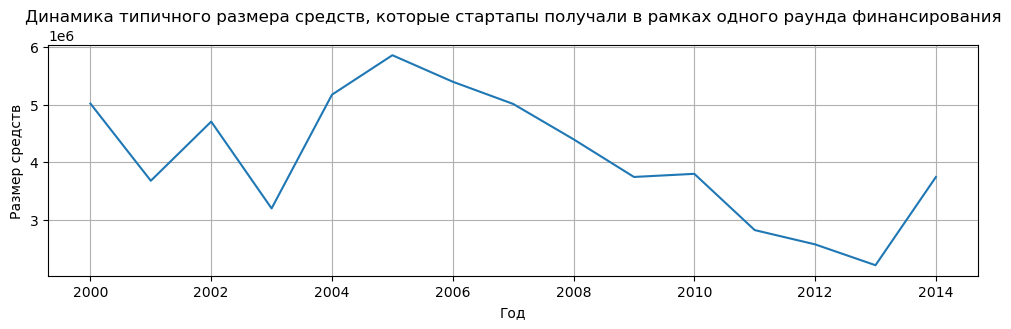

In [55]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(12, 3))

# Строим гистограмму с помощью pandas через plot(kind='bar')
df_investments.groupby(df_investments['mid_funding_at'].dt.year)['funding_avg_usd'].mean().plot(
               kind='line', # Тип графика - столбчатая диаграмма
               rot=0, # Градус вращения подписи по оси Х
               title=f'Динамика типичного размера средств, которые стартапы получали в рамках одного раунда финансирования',
                legend=False
)
# Настраиваем оформление графика
plt.xlabel('Год')
plt.ylabel('Размер средств')
# Добавляем сетку графика
plt.grid()

# Выводим график
plt.show()

На основе получившейся таблицы построим график "Динамика общего количества раундов за каждый год", то есть насколько активно происходили инвестиции на рынке (чем больше раундов, тем выше активность).

In [56]:
# найдем общее количество раундов за каждый год
df_investments.groupby(df_investments['mid_funding_at'].dt.year)['funding_rounds'].sum()

mid_funding_at
2000      122.0
2001       84.0
2002      107.0
2003      128.0
2004      189.0
2005      958.0
2006     1881.0
2007     2849.0
2008     3686.0
2009     4669.0
2010     6199.0
2011     7617.0
2012     9750.0
2013    12945.0
2014     7244.0
Name: funding_rounds, dtype: float64

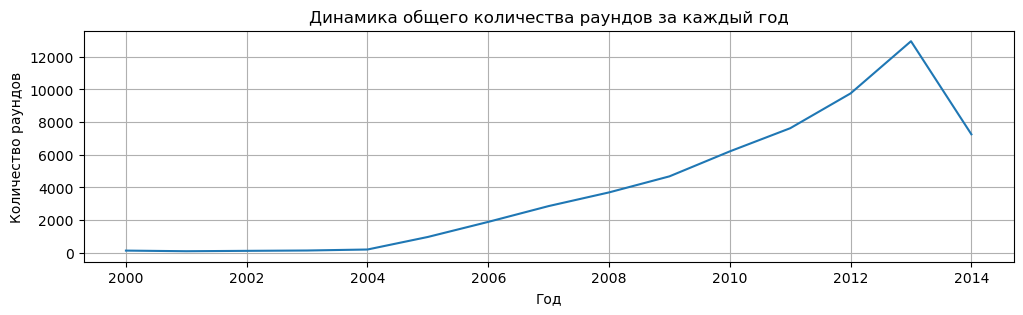

In [57]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(12, 3))

# Строим гистограмму с помощью pandas через plot(kind='bar')
df_investments.groupby(df_investments['mid_funding_at'].dt.year)['funding_rounds'].sum().plot(
               kind='line', # Тип графика - столбчатая диаграмма
               rot=0, # Градус вращения подписи по оси Х
               title=f'Динамика общего количества раундов за каждый год',
                legend=False
)
# Настраиваем оформление графика
plt.xlabel('Год')
plt.ylabel('Количество раундов')
# Добавляем сетку графика
plt.grid()

# Выводим график
plt.show()

В 2005 году типичный размер средств, собранных в рамках одного раунда, был максимальным и составил 5.855185e+06.
С 2005 по 2013 наблюдалось снижение типичного размера средств, собранного в рамках одного раунда, в 2014 году пошел подъем и составил 3.741692e+06. Зато общее количество раундов за год возрастало с 2000 до 2013 года, а в 2014 году пошел спад и составил 7244.

### 4.2 Динамика размера общего финансирования по массовым сегментам рынка для растущих в 2014 году сегментов

Составьте сводную таблицу, в которой указывается суммарный размер общего финансирования `funding_total_usd` по годам и сегментам рынка. Отберите из неё только те сегменты, которые показывали рост размера суммарного финансирования в 2014 году по сравнению с 2013.

На графике отразим, как менялся суммарный размер общего финансирования в каждом из отобранных сегментов по годам. Рассмотрим только массовые сегменты, а средние и нишевые исключим.

In [58]:
# группируем данные по году и сегменту и находим суммарный размер
table_sum_funding=df_investments.groupby(['market', df_investments['mid_funding_at'].dt.year])['funding_total_usd'].sum().unstack()
# фильтруем
table_sum_funding=table_sum_funding[table_sum_funding[2013]<table_sum_funding[2014]]
# Удаляем сегменты 'mid' и 'niche'
table_sum_funding = table_sum_funding.drop(['mid', 'niche'], errors='ignore')
display(table_sum_funding)

mid_funding_at,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014
market,,,,,,,,,,,,,,,
Apps,NaN,NaN,NaN,NaN,NaN,NaN,1310600.0,NaN,4300000.0,7219000.0,6123779.0,18374071.0,32601125.0,28868621.0,66237730.0
Big Data,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7780000.0,2452515.0,597375.0,39233297.0,60369158.0,86413341.0,78698922.0,79232600.0
Design,NaN,NaN,NaN,NaN,NaN,9300000.0,707000.0,10800000.0,5944302.0,2150144.0,17239975.0,8899967.0,39630692.0,60958835.0,68988516.0
Internet,10000000.0,NaN,1100000.0,NaN,10500000.0,1775000.0,5000.0,4495379.0,23412964.0,38195773.0,36657500.0,36859032.0,28288685.0,69732096.0,117830756.0
Manufacturing,56659310.0,2368582.0,NaN,4269608.0,3000000.0,61770000.0,163957751.0,147726051.0,173054260.0,422862531.0,244329661.0,561639285.0,522205168.0,393936634.0,416332314.0
Medical,24000000.0,NaN,NaN,NaN,NaN,11090000.0,20250000.0,2100000.0,28812744.0,11566200.0,25590338.0,28540962.0,44039600.0,64469424.0,175236064.0
Real Estate,2500000.0,NaN,5275000.0,6292200.0,NaN,250000.0,2080000.0,33220000.0,46613100.0,38840213.0,37344608.0,20015128.0,77320857.0,92207655.0,115567364.0
SaaS,NaN,NaN,2000000.0,NaN,NaN,5240000.0,4791121.0,14652595.0,27226900.0,13536585.0,32609390.0,32223749.0,49699912.0,79576613.0,92807752.0
Startups,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5010387.0,460700.0,2111966.0,19654403.0,12333782.0,18080552.0,41501837.0


<Figure size 1000x500 with 0 Axes>

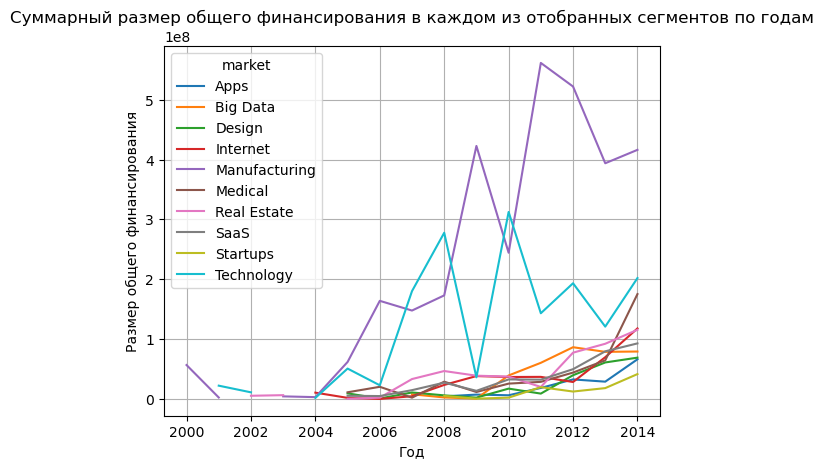

In [59]:
# Транспонируем таблицу, если нужно, чтобы годы были на оси X
table_sum_funding = table_sum_funding.T

# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(10, 5))

# Строим график
table_sum_funding.plot(
    kind='line',  # Тип графика - столбчатая диаграмма
    rot=0,       # Градус вращения подписи по оси Х
    title=f'Суммарный размер общего финансирования в каждом из отобранных сегментов по годам',
    legend=True
)

# Настраиваем оформление графика
plt.xlabel('Год')
plt.ylabel('Размер общего финансирования')
# Добавляем сетку графика
plt.grid()

# Выводим график
plt.show()

Сегменты Manufacturing  и Medical показывают наиболее быстрый и уверенный рост. В сегменте Technology размер общего финансирования происходит резкими скачками:то спад, то подъем. В остальных сегментах размер общего финансирования увеличивается постепенно, без резких скачков сниз.

### 4.3 Годовая динамика доли возвращённых средств по типам финансирования

Заказчик хочет знать, какая часть вложенных или выданных денег со временем возвращается обратно инвесторам или финансистам. Ваша цель — для каждого года и каждого вида финансирования рассчитать нормированные значения возврата средств: то есть какую долю возвращённые средства составляют от предоставленных. При этом слишком большие аномальные значения, то есть неадекватные выбросы, нужно заменить на пропуски.

Совет: когда будете делить сумму возвращённых средств на суммарный объём привлечённого финансирования по конкретному году, добавьте к знаменателю небольшое число, например `1e-60`. Это поможет избежать деления на ноль.

Выведем суммарный объём привлечённого финансирования каждого вида по конкретному году

In [60]:
#создадим таблицу с суммарным объём привлечённого финансирования каждого вида по конкретному году
gr=df_investments.groupby(df_investments['mid_funding_at'].dt.year)[['seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note', 'debt_financing', 'angel',
              'grant', 'private_equity', 'post_ipo_equity', 'post_ipo_debt', 'secondary_market', 'product_crowdfunding']].sum()
display(gr)

,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
mid_funding_at,,,,,,,,,,,,,
2000,1.675914e+07,3.753622e+08,0.0,215502640.0,0.0,1.400000e+07,24086333.0,293114.0,0.000000e+00,3.467747e+06,0.000000e+00,7718867.0,0.0
2001,2.639896e+07,2.852207e+08,0.0,46524067.0,1500000.0,5.829217e+06,1000000.0,100000.0,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.0
2002,1.046519e+07,3.423629e+08,0.0,42323731.0,0.0,1.530967e+07,3000000.0,0.0,4.644188e+07,3.000000e+05,0.000000e+00,0.0,0.0
2003,1.531836e+07,4.002344e+08,0.0,10280000.0,0.0,1.050000e+06,5629661.0,16850717.0,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.0
2004,1.810473e+07,7.230162e+08,0.0,98758160.0,0.0,3.081662e+07,11013741.0,14027534.0,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.0
2005,3.942520e+07,4.902948e+09,0.0,8871332.0,0.0,1.017207e+08,60914621.0,6266481.0,5.000000e+06,4.796022e+06,0.000000e+00,0.0,0.0
2006,6.679477e+07,9.200694e+09,933057.0,71842903.0,11807857.0,1.408484e+08,70756153.0,6147500.0,3.582024e+07,0.000000e+00,0.000000e+00,0.0,0.0
2007,1.922965e+08,1.215159e+10,0.0,109649902.0,14116788.0,6.579016e+08,201152441.0,34237779.0,1.958479e+08,1.200000e+07,0.000000e+00,0.0,0.0
2008,3.020030e+08,1.448512e+10,0.0,143785523.0,28600902.0,4.286221e+08,249299613.0,23485347.0,1.917563e+08,3.600000e+07,0.000000e+00,0.0,1000000.0


In [61]:
df_returns

,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
year,,,,,,,,,,,,,
2000,16.70,55.40,0.00,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.00,0.20,0.00
2001,2.88,23.49,0.00,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.00,0.46,0.00
2002,6.59,209.42,0.00,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.00,0.06,0.00
2003,7.74,233.86,0.00,9.40,0.01,1.09,3.41,0.0,1.62,2.11,0.00,0.08,0.00
2004,9.93,555.90,0.00,33.19,0.01,13.55,9.18,0.0,2.19,3.38,0.00,0.55,0.00
2005,26.60,2628.92,0.00,9.51,0.02,35.09,31.06,0.0,2.40,3.51,0.00,0.05,0.00
2006,61.81,3100.18,0.19,46.74,1.78,113.21,47.75,0.0,16.67,20.58,0.00,0.12,0.00
2007,70.41,3585.37,0.01,55.37,3.22,125.68,164.51,0.0,88.81,24.36,0.00,0.57,0.00
2008,89.72,2717.02,0.03,41.02,1.71,397.54,102.83,0.0,130.38,84.28,0.00,0.47,0.00


In [62]:
doly=df_returns*1000000/(gr+1e-60)
display(doly)

,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
year,,,,,,,,,,,,,
2000,0.996471,0.147591,0.000000e+00,0.362919,0.000000e+00,0.618571,0.266956,0.0,0.000000e+00,2.710694e-01,0.000000,2.591054e-02,0.000000
2001,0.109095,0.082357,0.000000e+00,0.462126,6.666667e-03,0.770258,1.180000,0.0,0.000000e+00,4.600000e+65,0.000000,4.600000e+65,0.000000
2002,0.629707,0.611690,0.000000e+00,0.608878,2.000000e+64,0.223388,1.136667,0.0,3.251376e-02,1.133333e+00,0.000000,6.000000e+64,0.000000
2003,0.505276,0.584308,0.000000e+00,0.914397,1.000000e+64,1.038095,0.605720,0.0,1.620000e+66,2.110000e+66,0.000000,8.000000e+64,0.000000
2004,0.548476,0.768862,0.000000e+00,0.336073,1.000000e+64,0.439698,0.833504,0.0,2.190000e+66,3.380000e+66,0.000000,5.500000e+65,0.000000
2005,0.674695,0.536192,0.000000e+00,1.071992,2.000000e+64,0.344964,0.509894,0.0,4.800000e-01,7.318565e-01,0.000000,5.000000e+64,0.000000
2006,0.925372,0.336951,2.036317e-01,0.650586,1.507471e-01,0.803772,0.674853,0.0,4.653793e-01,2.058000e+67,0.000000,1.200000e+65,0.000000
2007,0.366153,0.295054,1.000000e+64,0.504971,2.280972e-01,0.191032,0.817837,0.0,4.534642e-01,2.030000e+00,0.000000,5.700000e+65,0.000000
2008,0.297083,0.187573,3.000000e+64,0.285286,5.978832e-02,0.927484,0.412476,0.0,6.799254e-01,2.341111e+00,0.000000,4.700000e+65,0.000000


Удалим аномальные значения(т.к. в суммарном объёме привлечённого финансирования где-то были нули и в знаменатели мы добавили маленькое число)

In [63]:
# Применяем функцию к каждому элементу таблицы
doly = doly.apply(lambda col: col.map(lambda x: x if x <= 1 else float('nan')))
display(doly)

,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
year,,,,,,,,,,,,,
2000,0.996471,0.147591,0.000000,0.362919,0.000000,0.618571,0.266956,0.0,0.000000,0.271069,0.000000,0.025911,0.000000
2001,0.109095,0.082357,0.000000,0.462126,0.006667,0.770258,NaN,0.0,0.000000,NaN,0.000000,NaN,0.000000
2002,0.629707,0.611690,0.000000,0.608878,NaN,0.223388,NaN,0.0,0.032514,NaN,0.000000,NaN,0.000000
2003,0.505276,0.584308,0.000000,0.914397,NaN,NaN,0.605720,0.0,NaN,NaN,0.000000,NaN,0.000000
2004,0.548476,0.768862,0.000000,0.336073,NaN,0.439698,0.833504,0.0,NaN,NaN,0.000000,NaN,0.000000
2005,0.674695,0.536192,0.000000,NaN,NaN,0.344964,0.509894,0.0,0.480000,0.731857,0.000000,NaN,0.000000
2006,0.925372,0.336951,0.203632,0.650586,0.150747,0.803772,0.674853,0.0,0.465379,NaN,0.000000,NaN,0.000000
2007,0.366153,0.295054,NaN,0.504971,0.228097,0.191032,0.817837,0.0,0.453464,NaN,0.000000,NaN,0.000000
2008,0.297083,0.187573,NaN,0.285286,0.059788,0.927484,0.412476,0.0,0.679925,NaN,0.000000,NaN,0.000000


Постройте график, на котором отобразите нормированные значения возврата средств для типов финансирования `venture`, `debt_financing`, `private_equity`, `seed` и `angel`.

<Figure size 1500x1000 with 0 Axes>

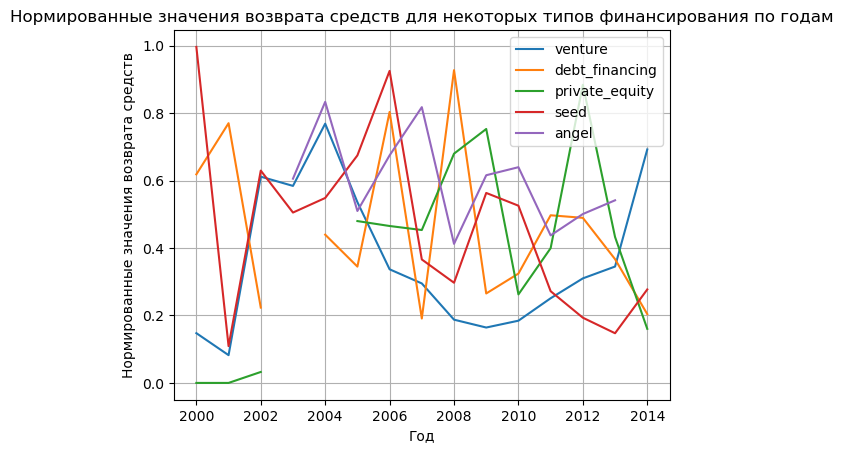

In [64]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(15, 10))

# Строим график
doly[['venture', 'debt_financing', 'private_equity', 'seed', 'angel']].plot(
    kind='line',  # Тип графика - столбчатая диаграмма
    rot=0,       # Градус вращения подписи по оси Х
    title=f'Нормированные значения возврата средств для некоторых типов финансирования по годам',
    legend=True
)

# Настраиваем оформление графика
plt.xlabel('Год')
plt.ylabel('Нормированные значения возврата средств')
# Добавляем сетку графика
plt.grid()

# Выводим график
plt.show()

В типе финансирования venture наблюдается наиболее устойчивый рост показателя. в Остальных типах финансирования - debt_financing, private_equity, seed и angel - нормированные значения возврата средств возврастают и снижаются скачками.


## Шаг 5. Итоговый вывод и рекомендации

Были загружены данные  из двух датафреймов `df_investments` и `df_returns`. 

При первичном ознакомлении с данными и их предварительной обработке были получены следующие результаты:

Датасет `df_investments` содержит 40 столбцов и 54294 строк с информацией о компаниях и состоявшемся финансировании. В этом датасете мы:
- Изменили тип данных на int и оптимизировали столбцы funding_rounds,participants и founded_year. 
- В столбце funding_total_usd убрали выделение разрядов и изменили тип данных на float64 .
- Изменили тип данных на datetime в столбцах `founded_at`, `founded_month`, `first_funding_at`, `mid_funding_at`, `last_funding_at`.
- Обработали текстовые данные, а именно заполнили пропущенные значения в столбцах `country_code`, `state_code` и `region` на основании значений в столбце `city`.
- Обработайли полные дубликаты в данных и пропуски в `funding_total_usd`. 
- Заполнили пропуски в значениях `mid_funding_at` на основании значений в столбцах `first_funding_at` и `last_funding_at`. В качестве нового значения вместо пропусков взяли приблизительно середину интервала между этими двумя датами.
- Обработали полные дубликаты в данных, явных дубликатов не оказалось. После всех обработок, мы удалили 13390 строк, что составляет 24.7%.
- Выяснили, что 4871 компаний с аномальным объемом общего финансирования, мы удалили выбросы и компании, если они получали финансирование в годы, когда было зафиксировано меньше 50 раундов за год.

Датасет `df_returns` содержит 14 столбцов и 15 строк с информацией о сумме возвратов по типам финансирования. В этом датасете мы:
- Сделали столбец `year` индексом всего датасета.

У большинства компаний было единичное финансирование (58.9%, 24112 компаний); компаний, у которых срок финансирования более года составили 30% (12385 компаний); и компаниии, у которых срок финансирования до года - 10% (4407 компаний). Компании, у которых срок финансирования был менее года - объем привлеченных инвестиций оказался меньше всего (7%); компании, у которых срок финансирования составил больше года - объем привлеченных инвестиций оказался самым большим (62 %); и компании, у которых было единичное финансирования - объем привлеченных инвестиций составил 31% от всей суммы инвестиций.

Основное количество компаний сосредоточено в массовом сегменте - 33732 компаний, в среднем сегменте - 3839 компаний и в нишевом - 830. 

venture,  seed , debt_financing наиболее используемые типы финансирования и общая сумма финансирования по этим типам самая большая. secondary_market  практически не используется и сумма финансирования самая маленькая.
Тип финансирования grant компании используют часто, но общая сумма финансирования небольшая. И наоборот тип финансирования post_ipo_equity и post_ipo_debt практически не используют компании, но общая сумма финансирования по этому типу значительная.
Самые большие суммарные объёмы возвратов за весь период от типа финансирования venture. В типе финансирования grant суммарные объёмы возвратов за весь период составляют 0.

В типе финансирования venture наблюдается наиболее устойчивый рост показателя возврата средств, в остальных типах финансирования - debt_financing, private_equity, seed и angel - нормированные значения возврата средств возврастают и снижаются скачками.

В 2005 году типичный размер средств, собранных в рамках одного раунда, был максимальным и составил 5.855185e+06. С 2005 по 2013 наблюдалось снижение типичного размера средств, собранного в рамках одного раунда, в 2014 году пошел подъем и составил 3.741692e+06. Зато общее количество раундов за год возрастало с 2000 до 2013 года, а в 2014 году пошел спад и составил 7244.

Сегменты Manufacturing и Medical показывают наиболее быстрый и уверенный рост. В сегменте Technology размер общего финансирования происходит резкими скачками:то спад, то подъем. В остальных сегментах размер общего финансирования увеличивается постепенно, без резких скачков сниз.

В качестве рекомендаций стоит обратить внимание на сегменты Manufacturing и Medical, они показывают наиболее быстрый и уверенный рост. Наиболее уместный тип финансирования - venture, ткобщая сумма финансирования по этому типу самая большая, и в этом типе финансирования самые большие суммарные объёмы возвратов за весь период, и тут наблюдается наиболее устойчивый рост показателя возврата средств

